In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
# CodeAlpha Internship - Task 2
# Unemployment Analysis with Python

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# 1. Load dataset
df = pd.read_csv("/kaggle/input/datasets/riyadhdata262/unemployment-in-india-dataset/Unemployment in India.csv")

In [3]:
# 2. Data cleaning
df.columns = df.columns.str.strip()
df = df.dropna(how="all").drop_duplicates()

df["Date"] = pd.to_datetime(
    df["Date"].astype(str).str.strip(),
    format="%d-%m-%Y"
)

df["Area"] = df["Area"].str.strip()
df["Region"] = df["Region"].str.strip()

df["Estimated Unemployment Rate (%)"] = pd.to_numeric(
    df["Estimated Unemployment Rate (%)"],
    errors="coerce"
)

df = df.dropna(subset=[
    "Date", "Region", "Area",
    "Estimated Unemployment Rate (%)"
])

print("Cleaned Dataset Shape:", df.shape)
print("\nMissing Values:")
print(df.isnull().sum())

Cleaned Dataset Shape: (740, 7)

Missing Values:
Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Area                                       0
dtype: int64


In [4]:
# 3. Basic exploration
print("\nDataset Information:")
print(df.describe())


Dataset Information:
                                Date  Estimated Unemployment Rate (%)  \
count                            740                       740.000000   
mean   2019-12-12 18:36:58.378378496                        11.787946   
min              2019-05-31 00:00:00                         0.000000   
25%              2019-08-31 00:00:00                         4.657500   
50%              2019-11-30 00:00:00                         8.350000   
75%              2020-03-31 00:00:00                        15.887500   
max              2020-06-30 00:00:00                        76.740000   
std                              NaN                        10.721298   

       Estimated Employed  Estimated Labour Participation Rate (%)  
count        7.400000e+02                               740.000000  
mean         7.204460e+06                                42.630122  
min          4.942000e+04                                13.330000  
25%          1.190404e+06                   

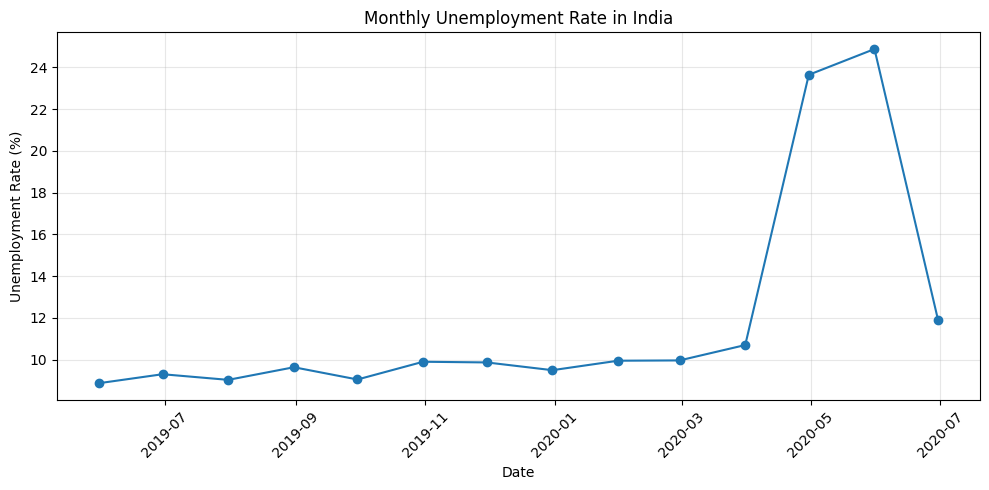

In [5]:
# 4. Monthly unemployment trend
monthly = df.groupby("Date")[
    "Estimated Unemployment Rate (%)"
].mean()

plt.figure(figsize=(10, 5))
plt.plot(monthly.index, monthly.values, marker="o")
plt.title("Monthly Unemployment Rate in India")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("monthly_unemployment.png", dpi=300)
plt.show()

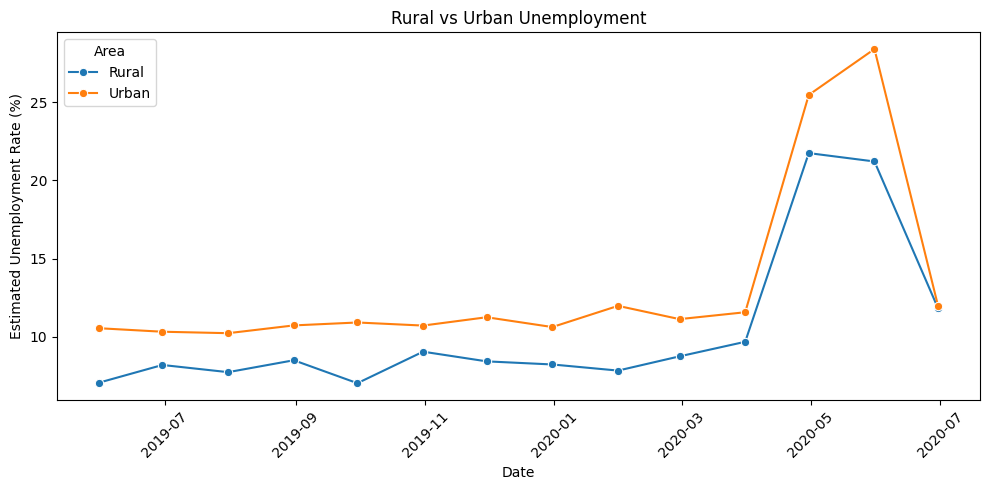

In [6]:
# 5. Rural vs Urban comparison
area_data = df.groupby(["Date", "Area"])[
    "Estimated Unemployment Rate (%)"
].mean().reset_index()

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=area_data,
    x="Date",
    y="Estimated Unemployment Rate (%)",
    hue="Area",
    marker="o"
)
plt.title("Rural vs Urban Unemployment")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("rural_vs_urban.png", dpi=300)
plt.show()


Pre-COVID vs COVID Average:
Period
COVID Period    17.77
Pre-COVID        9.51
Name: Estimated Unemployment Rate (%), dtype: float64


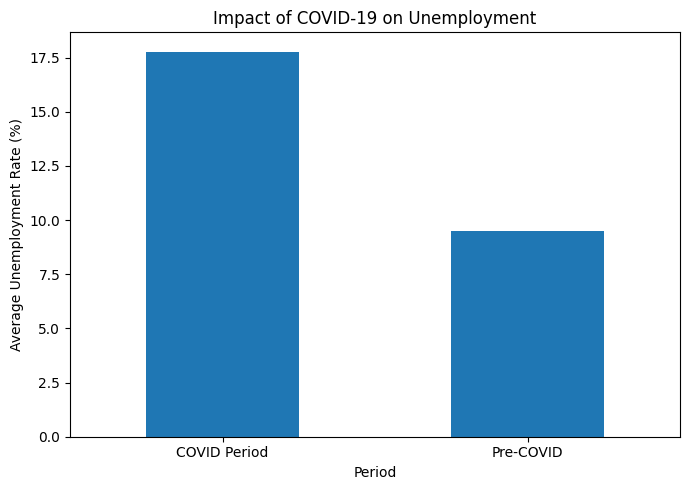

In [7]:
# 6. COVID-19 impact analysis
df["Period"] = df["Date"].apply(
    lambda date: "Pre-COVID"
    if date < pd.Timestamp("2020-03-01")
    else "COVID Period"
)

covid_data = df.groupby("Period")[
    "Estimated Unemployment Rate (%)"
].mean()

print("\nPre-COVID vs COVID Average:")
print(covid_data.round(2))

plt.figure(figsize=(7, 5))
covid_data.plot(kind="bar")
plt.title("Impact of COVID-19 on Unemployment")
plt.ylabel("Average Unemployment Rate (%)")
plt.xlabel("Period")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("covid_impact.png", dpi=300)
plt.show()

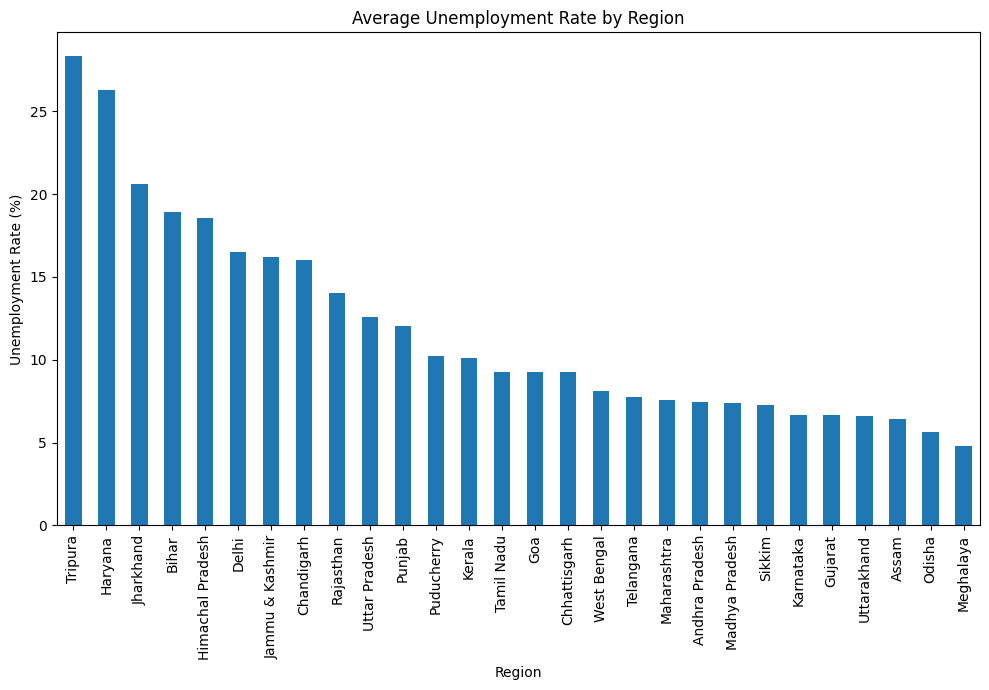

In [8]:
# 7. Regional unemployment comparison
region_data = df.groupby("Region")[
    "Estimated Unemployment Rate (%)"
].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 7))
region_data.plot(kind="bar")
plt.title("Average Unemployment Rate by Region")
plt.ylabel("Unemployment Rate (%)")
plt.tight_layout()
plt.savefig("regional_unemployment.png", dpi=300)
plt.show()

In [9]:
# 8. Final insights
print("\nTop 5 Regions with Highest Average Unemployment:")
print(region_data.head(5).round(2))

print("\nTop 5 Regions with Lowest Average Unemployment:")
print(region_data.tail(5).round(2))

print("\nProject Analysis Completed Successfully!")


Top 5 Regions with Highest Average Unemployment:
Region
Tripura             28.35
Haryana             26.28
Jharkhand           20.58
Bihar               18.92
Himachal Pradesh    18.54
Name: Estimated Unemployment Rate (%), dtype: float64

Top 5 Regions with Lowest Average Unemployment:
Region
Gujarat        6.66
Uttarakhand    6.58
Assam          6.43
Odisha         5.66
Meghalaya      4.80
Name: Estimated Unemployment Rate (%), dtype: float64

Project Analysis Completed Successfully!
